# Virginia Reality Check

**DS2002 capstone**

Answer the two questions below about Virginia men's basketball using saved data:

**Questions**

1. **Has Virginia's record been earned against strong opponents?**
2. **Who carries Virginia?**

## 0. Setup

In [1]:
import json
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

PULL_DATE = "2026-11-21"
RAW = Path("raw")
DB_PATH = Path("uva.db")
CHARTS = Path("charts")
CHARTS.mkdir(exist_ok=True)

UVA_ID = "258"

# Decision log
decision_log = []

def log(step, decision, rows_before, rows_after):
    decision_log.append({
        "step": step,
        "decision": decision,
        "rows_before": rows_before,
        "rows_after": rows_after,
        "rows_changed": rows_before - rows_after,
    })

## 1. Extract: read the saved raw files


| File | Source |
|---|---|
| `torvik_2027_team_results_<date>.csv` | Torvik ratings for every Division I team |
| `espn_schedule_<date>.json` | ESPN schedule, every Virginia game this season |
| `espn_summary_<game_id>_<date>.json` | ESPN box score, one per finished game |

In [2]:
torvik_raw = pd.read_csv(RAW / f"torvik_2027_team_results_{PULL_DATE}.csv")

with open(RAW / f"espn_schedule_{PULL_DATE}.json", encoding="utf-8") as f:
    schedule = json.load(f)

summary_files = sorted(RAW.glob(f"espn_summary_*_{PULL_DATE}.json"))
summaries = {}
for path in summary_files:
    with open(path, encoding="utf-8") as f:
        data = json.load(f)
    summaries[data["header"]["id"]] = data

print(f"Torvik teams:         {len(torvik_raw)}")
print(f"Games on schedule:    {len(schedule['events'])}")
print(f"Box score summaries:  {len(summaries)}")

Torvik teams:         365
Games on schedule:    31
Box score summaries:  7


## 2. Games: keep only finished games, convert start times to Eastern

ESPN records start times in UTC, which is five hours ahead of Eastern. An evening game in Charlottesville can show up with the next day's date in UTC, so I convert each time to `America/New_York` before taking the date.

In [3]:
rows = []
for event in schedule["events"]:
    comp = event["competitions"][0]
    uva = next(c for c in comp["competitors"] if c["team"]["id"] == UVA_ID)
    opp = next(c for c in comp["competitors"] if c["team"]["id"] != UVA_ID)
    rows.append({
        "game_id": event["id"],
        "start_utc": comp["date"],
        "completed": comp["status"]["type"]["completed"],
        "neutral_site": comp.get("neutralSite", False),
        "uva_home_away": uva["homeAway"],
        "opponent_id": opp["team"]["id"],
        "opponent_name": opp["team"]["location"],
        "uva_score": (uva.get("score") or {}).get("value"),
        "opp_score": (opp.get("score") or {}).get("value"),
    })
games_all = pd.DataFrame(rows)

# Keep only finished games
games = games_all[games_all["completed"]].copy()
log("games", "Kept only finished games (competitions[0].status.type.completed == True)",
    len(games_all), len(games))

# UTC -> Eastern, then take the date
games["start_utc"] = pd.to_datetime(games["start_utc"], utc=True)
games["start_et"] = games["start_utc"].dt.tz_convert("America/New_York")
games["game_date_et"] = games["start_et"].dt.strftime("%Y-%m-%d")
games["utc_date"] = games["start_utc"].dt.strftime("%Y-%m-%d")

date_shifted = (games["game_date_et"] != games["utc_date"]).sum()
log("games", f"Converted start times UTC -> Eastern; {date_shifted} games moved to the previous calendar day",
    len(games), len(games))

games["uva_score"] = games["uva_score"].astype(int)
games["opp_score"] = games["opp_score"].astype(int)
games["result"] = games.apply(lambda r: "W" if r["uva_score"] > r["opp_score"] else "L", axis=1)
games["location"] = games.apply(
    lambda r: "Neutral" if r["neutral_site"] else ("Home" if r["uva_home_away"] == "home" else "Away"), axis=1)

games[["game_id", "game_date_et", "utc_date", "opponent_name", "location", "uva_score", "opp_score", "result"]]

,game_id,game_date_et,utc_date,opponent_name,location,uva_score,opp_score,result
0,401920422,2026-11-03,2026-11-04,Drexel,Home,89,60,W
1,401920423,2026-11-06,2026-11-06,Northeastern,Home,97,72,W
2,401920424,2026-11-08,2026-11-08,Arkansas,Neutral,91,72,W
3,401920425,2026-11-10,2026-11-11,Bucknell,Home,95,61,W
4,401916297,2026-11-13,2026-11-14,Maryland,Away,87,83,W
5,401920426,2026-11-17,2026-11-18,Old Dominion,Home,85,65,W
6,401920427,2026-11-20,2026-11-21,Loyola Maryland,Home,103,61,W


## 3. Match each opponent to its Torvik row

Some schools have different names in the two sources. With so few opponents, the simplest fix is a small dictionary that maps ESPN's name to Torvik's. An opponent missing from Torvik isn't a Division I team, so it has no rating, and the decision log records it.

In [4]:
# ESPN name -> Torvik name (only where the two sources differ)
NAME_FIXES = {
    "Loyola Maryland": "Loyola MD",
    "NC State": "N.C. State",
}

torvik = torvik_raw.rename(columns={"team": "torvik_name"})
torvik_names = set(torvik["torvik_name"])

opponents = games[["opponent_id", "opponent_name"]].drop_duplicates().copy()
opponents["torvik_name"] = opponents["opponent_name"].map(lambda n: NAME_FIXES.get(n, n))
opponents["rated"] = opponents["torvik_name"].isin(torvik_names)

renamed = (opponents["opponent_name"] != opponents["torvik_name"]).sum()
log("teams", f"Renamed {renamed} ESPN opponent names to match Torvik spelling",
    len(opponents), len(opponents))

unrated = opponents[~opponents["rated"]]
log("teams", "Opponents with no Torvik row (non-Division I): "
    + (", ".join(unrated["opponent_name"]) if len(unrated) else "none"),
    len(opponents), len(opponents) - len(unrated))

opponents

,opponent_id,opponent_name,torvik_name,rated
0,2182,Drexel,Drexel,True
1,111,Northeastern,Northeastern,True
2,8,Arkansas,Arkansas,True
3,2083,Bucknell,Bucknell,True
4,120,Maryland,Maryland,True
5,295,Old Dominion,Old Dominion,True
6,2352,Loyola Maryland,Loyola MD,True


## 4. Flatten Virginia's box scores

One row per player per game with minutes, points, rebounds, steals, and blocks.
In each summary, `boxscore['players']` has one entry per team; Virginia's has `team.id == '258'`.
Players who were listed but did not play have an empty `stats` list, so they are dropped.

In [5]:
WANTED = ["minutes", "points", "rebounds", "steals", "blocks"]

pg_rows = []
for game_id, data in summaries.items():
    uva_box = next(t for t in data["boxscore"]["players"] if t["team"]["id"] == UVA_ID)
    block = uva_box["statistics"][0]
    keys = block["keys"]
    for a in block["athletes"]:
        row = {
            "game_id": game_id,
            "player_id": a["athlete"]["id"],
            "player_name": a["athlete"]["displayName"],
            "starter": a.get("starter", False),
        }
        if a["stats"]:
            stats = dict(zip(keys, a["stats"]))
            for k in WANTED:
                row[k] = int(stats[k]) if stats[k] not in ("", "--") else 0
        pg_rows.append(row)

player_games_all = pd.DataFrame(pg_rows)
player_games = player_games_all.dropna(subset=["points"]).copy()
for k in WANTED:
    player_games[k] = player_games[k].astype(int)
log("player_games", "Dropped roster rows for players who did not play (empty stats list)",
    len(player_games_all), len(player_games))

# Keep box scores only for games that are in the finished-games table
before = len(player_games)
player_games = player_games[player_games["game_id"].isin(games["game_id"])]
log("player_games", "Kept box score rows only for finished games", before, len(player_games))

print(f"{len(player_games)} player-game rows across {player_games['game_id'].nunique()} games")
player_games.head(10)

99 player-game rows across 7 games


,game_id,player_id,player_name,starter,minutes,points,rebounds,steals,blocks
0,401916297,5457336,Nolan Adekunle,True,19,0,2,1,0
1,401916297,5311846,Thijs De Ridder,True,32,20,7,2,0
2,401916297,5311844,Johann Grunloh,True,37,15,7,0,3
3,401916297,5176232,Sam Lewis,True,34,28,7,1,1
4,401916297,5150404,Chance Mallory,True,35,12,5,1,0
5,401916297,5106205,Kalu Anya,False,9,4,2,0,0
6,401916297,5239714,Martin Carrere,False,11,2,3,0,0
7,401916297,5174984,Jan Vide,False,3,0,0,0,0
8,401916297,5080790,Elijah Gertrude,False,19,6,0,0,0
9,401916297,4711267,Jurian Dixon,False,1,0,0,0,0


**Quick Check:** the sum of player points in each game should equal Virginia's final score from the schedule.

In [6]:
check = (player_games.groupby("game_id")["points"].sum().rename("box_score_points")
         .to_frame().join(games.set_index("game_id")["uva_score"]))
check["matches"] = check["box_score_points"] == check["uva_score"]
assert check["matches"].all(), "Box score points do not match the final score"

check

,box_score_points,uva_score,matches
game_id,,,
401916297,87,87,True
401920422,89,89,True
401920423,97,97,True
401920424,91,91,True
401920425,95,95,True
401920426,85,85,True
401920427,103,103,True


Everything looks good so continue!

## 5. Load into SQLite (`uva.db`)

The database has four tables and each one has a primary key. I load them with `INSERT OR REPLACE` so running the load again updates the existing rows instead of adding duplicate

| Table | Primary key | Contents |
|---|---|---|
| `teams` | `team_id` | Virginia and each opponent, with the ESPN and Torvik names |
| `ratings` | `torvik_name` | Torvik rating for every Division I team |
| `games` | `game_id` | One row per finished Virginia game |
| `player_games` | `(game_id, player_id)` | One row per Virginia player per game |

In [7]:
SCHEMA = """
CREATE TABLE IF NOT EXISTS teams (
    team_id      TEXT PRIMARY KEY,
    espn_name    TEXT NOT NULL,
    torvik_name  TEXT,
    rated        INTEGER NOT NULL
);
CREATE TABLE IF NOT EXISTS ratings (
    torvik_name  TEXT PRIMARY KEY,
    conf         TEXT,
    record       TEXT,
    barthag      REAL,
    sos          REAL,
    pull_date    TEXT
);
CREATE TABLE IF NOT EXISTS games (
    game_id       TEXT PRIMARY KEY,
    game_date_et  TEXT NOT NULL,
    start_utc     TEXT NOT NULL,
    opponent_id   TEXT NOT NULL REFERENCES teams(team_id),
    location      TEXT,
    uva_score     INTEGER,
    opp_score     INTEGER,
    result        TEXT
);
CREATE TABLE IF NOT EXISTS player_games (
    game_id      TEXT NOT NULL REFERENCES games(game_id),
    player_id    TEXT NOT NULL,
    player_name  TEXT NOT NULL,
    starter      INTEGER,
    minutes      INTEGER,
    points       INTEGER,
    rebounds     INTEGER,
    steals       INTEGER,
    blocks       INTEGER,
    PRIMARY KEY (game_id, player_id)
);
"""

teams_rows = [(UVA_ID, "Virginia", "Virginia", 1)] + [
    (r.opponent_id, r.opponent_name, r.torvik_name if r.rated else None, int(r.rated))
    for r in opponents.itertuples()
]
ratings_rows = [
    (r.torvik_name, r.conf, r.record, float(r.barthag), float(r.sos), PULL_DATE)
    for r in torvik.itertuples()
]
games_rows = [
    (r.game_id, r.game_date_et, r.start_utc.isoformat(), r.opponent_id, r.location,
     r.uva_score, r.opp_score, r.result)
    for r in games.itertuples()
]
pg_rows_db = [
    (r.game_id, r.player_id, r.player_name, int(r.starter), r.minutes, r.points,
     r.rebounds, r.steals, r.blocks)
    for r in player_games.itertuples()
]


def load(db_path=DB_PATH):
    with sqlite3.connect(db_path) as con:
        con.executescript(SCHEMA)
        con.executemany("INSERT OR REPLACE INTO teams VALUES (?,?,?,?)", teams_rows)
        con.executemany("INSERT OR REPLACE INTO ratings VALUES (?,?,?,?,?,?)", ratings_rows)
        con.executemany("INSERT OR REPLACE INTO games VALUES (?,?,?,?,?,?,?,?)", games_rows)
        con.executemany("INSERT OR REPLACE INTO player_games VALUES (?,?,?,?,?,?,?,?,?)", pg_rows_db)


def row_counts(db_path=DB_PATH):
    with sqlite3.connect(db_path) as con:
        return {t: con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
                for t in ["teams", "ratings", "games", "player_games"]}


load()
first = row_counts()
first

{'teams': 8, 'ratings': 365, 'games': 7, 'player_games': 99}

**Rerun check:** loading a second time must leave every row count unchanged.

In [8]:
load()
second = row_counts()

rerun = pd.DataFrame({"first_load": first, "second_load": second})
rerun["unchanged"] = rerun["first_load"] == rerun["second_load"]
assert rerun["unchanged"].all()
rerun

,first_load,second_load,unchanged
teams,8,8,True
ratings,365,365,True
games,7,7,True
player_games,99,99,True


Both loads have same amount of rows so good to go!

## 6. Q1. How strong have Virginia's opponents been?

Barthag is Torvik's estimate of the chance a team would beat an average Division I team on a neutral court. It runs from 0 to 1, so 0.95 describes one of the best teams in the country and 0.5 describes an average team.


In [9]:
def query(sql):
    with sqlite3.connect(DB_PATH) as con:
        return pd.read_sql_query(sql, con)

q1_opponents = query("""
    SELECT g.game_date_et,
           t.espn_name        AS opponent,
           g.location,
           g.uva_score || '-' || g.opp_score AS score,
           r.barthag
    FROM games g
    JOIN teams t        ON t.team_id = g.opponent_id
    LEFT JOIN ratings r ON r.torvik_name = t.torvik_name
    ORDER BY r.barthag DESC
""")

q1_opponents

,game_date_et,opponent,location,score,barthag
0,2026-11-08,Arkansas,Neutral,91-72,0.880650
1,2026-11-13,Maryland,Away,87-83,0.850969
2,2026-11-17,Old Dominion,Home,85-65,0.449521
3,2026-11-06,Northeastern,Home,97-72,0.399354
4,2026-11-03,Drexel,Home,89-60,0.346226
5,2026-11-10,Bucknell,Home,95-61,0.149394
6,2026-11-20,Loyola Maryland,Home,103-61,0.116648


In [10]:
q1_summary = query("""
    SELECT COUNT(*)                                   AS games,
           SUM(CASE WHEN r.barthag IS NULL THEN 1 ELSE 0 END) AS unrated_opponents,
           ROUND(AVG(r.barthag), 3)                   AS avg_opp_barthag,
           (SELECT ROUND(sos, 3) FROM ratings WHERE torvik_name = 'Virginia')     AS uva_torvik_sos,
           (SELECT ROUND(barthag, 3) FROM ratings WHERE torvik_name = 'Virginia') AS uva_barthag,
           SUM(CASE WHEN r.barthag >= 0.5 THEN 1 ELSE 0 END) AS above_average_opps
    FROM games g
    JOIN teams t        ON t.team_id = g.opponent_id
    LEFT JOIN ratings r ON r.torvik_name = t.torvik_name
""")
q1_summary

,games,unrated_opponents,avg_opp_barthag,uva_torvik_sos,uva_barthag,above_average_opps
0,7,0,0.456,0.423,0.944,2


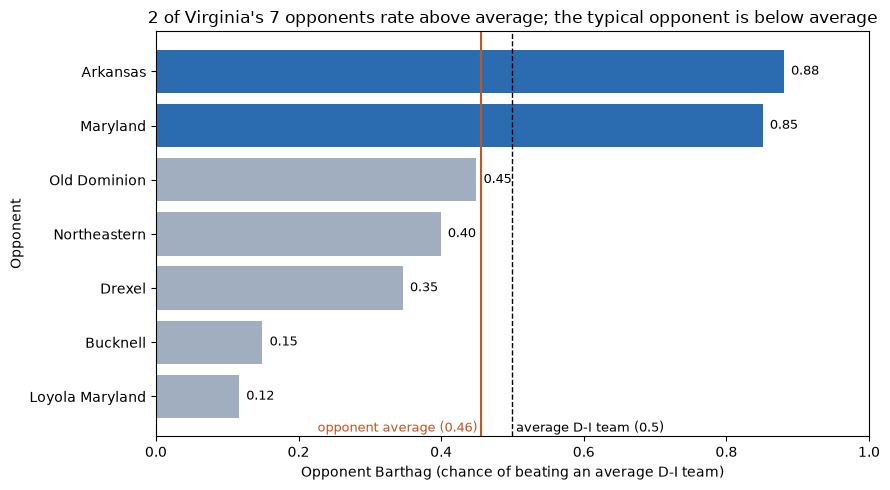

In [11]:
s = q1_summary.iloc[0]
plot = q1_opponents.sort_values("barthag")

fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#2b6cb0" if b >= 0.5 else "#a0aec0" for b in plot["barthag"]]
ax.barh(plot["opponent"], plot["barthag"], color=colors)
ax.axvline(0.5, color="black", linestyle="--", linewidth=1)
ax.text(0.505, -0.65, "average D-I team (0.5)", fontsize=9, ha="left")
ax.axvline(s["avg_opp_barthag"], color="#c05621", linewidth=1.5)
ax.text(s["avg_opp_barthag"] - 0.005, -0.65,
        f"opponent average ({s['avg_opp_barthag']:.2f})", fontsize=9, color="#c05621", ha="right")
for i, b in enumerate(plot["barthag"]):
    ax.text(b + 0.01, i, f"{b:.2f}", va="center", fontsize=9)
ax.set_xlim(0, 1)
ax.set_xlabel("Opponent Barthag (chance of beating an average D-I team)")
ax.set_ylabel("Opponent")
ax.set_title(f"{int(s['above_average_opps'])} of Virginia's {int(s['games'])} opponents rate above average; "
             f"the typical opponent is below average")
plt.tight_layout()
plt.savefig(CHARTS / "q1_opponent_strength.png", dpi=150)
plt.show()

## 7. Q2. Who carries Virginia?

In [12]:
q2 = query("""
    WITH team AS (SELECT SUM(points) AS team_points FROM player_games)
    SELECT player_name,
           COUNT(*)        AS games,
           SUM(minutes)    AS minutes,
           SUM(points)     AS points,
           SUM(rebounds)   AS rebounds,
           SUM(steals)     AS steals,
           SUM(blocks)     AS blocks,
           ROUND(100.0 * SUM(points) / (SELECT team_points FROM team), 1) AS pct_team_points
    FROM player_games
    GROUP BY player_id, player_name
    ORDER BY points DESC
""")

q2

,player_name,games,minutes,points,rebounds,steals,blocks,pct_team_points
0,Thijs De Ridder,7,187,129,54,16,3,19.9
1,Sam Lewis,7,194,121,27,9,2,18.7
2,Chance Mallory,7,188,94,26,15,0,14.5
3,Johann Grunloh,7,203,87,50,3,21,13.4
4,Elijah Gertrude,7,112,58,16,11,4,9.0
5,Nolan Adekunle,7,161,45,22,7,2,7.0
6,Martin Carrere,7,79,28,20,1,3,4.3
7,Jurian Dixon,7,52,24,6,3,0,3.7
8,Jan Vide,7,51,20,10,6,1,3.1
9,Kalu Anya,7,87,19,12,4,1,2.9


In [13]:
team_points = int(q2["points"].sum())
top5 = q2.head(5)
top1, top2 = q2.iloc[0], q2.iloc[1]

print(f"Games covered:          {player_games['game_id'].nunique()}")
print(f"Team points:            {team_points}")
print(f"Leading scorer:         {top1['player_name']} - {top1['points']} pts ({top1['pct_team_points']}%)")
print(f"Top two combined:       {top1['pct_team_points'] + top2['pct_team_points']:.1f}%")
print(f"Top five combined:      {top5['pct_team_points'].sum():.1f}%")
print(f"Players with 10%+:      {(q2['pct_team_points'] >= 10).sum()}")
print()
for stat in ["rebounds", "steals", "blocks"]:
    leader = q2.sort_values(stat, ascending=False).iloc[0]
    print(f"{stat.capitalize():<10} leader: {leader['player_name']} ({leader[stat]})")

Games covered:          7
Team points:            647
Leading scorer:         Thijs De Ridder - 129 pts (19.9%)
Top two combined:       38.6%
Top five combined:      75.5%
Players with 10%+:      4

Rebounds   leader: Thijs De Ridder (54)
Steals     leader: Thijs De Ridder (16)
Blocks     leader: Johann Grunloh (21)


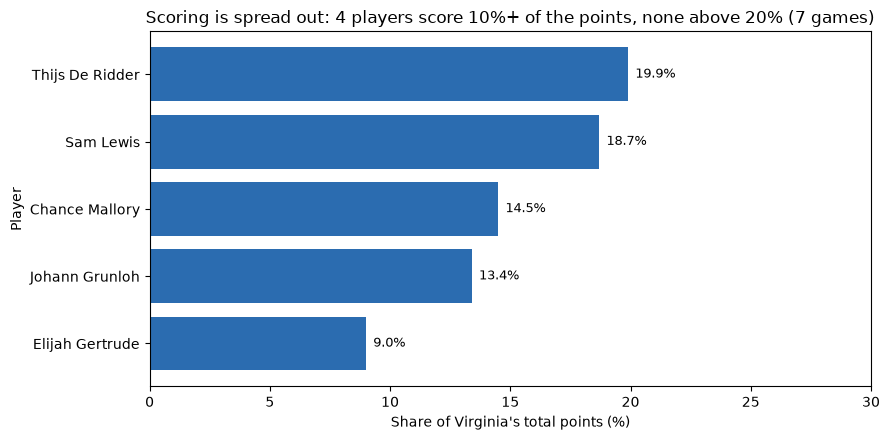

In [14]:
plot = top5.sort_values("pct_team_points")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(plot["player_name"], plot["pct_team_points"], color="#2b6cb0")
for i, v in enumerate(plot["pct_team_points"]):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=9)
ax.set_xlim(0, max(30, plot["pct_team_points"].max() + 5))
ax.set_xlabel("Share of Virginia's total points (%)")
ax.set_ylabel("Player")
n_games = player_games["game_id"].nunique()
n_10 = (q2["pct_team_points"] >= 10).sum()
ax.set_title(f"Scoring is spread out: {n_10} players score 10%+ of the points, "
             f"none above {top1['pct_team_points']:.0f}% ({n_games} games)")
plt.tight_layout()
plt.savefig(CHARTS / "q2_scoring_share.png", dpi=150)
plt.show()

## 8. Decision log

In [15]:
decision_log_df = pd.DataFrame(decision_log)
decision_log_df.to_csv("decision_log.csv", index=False)
decision_log_df

,step,decision,rows_before,rows_after,rows_changed
0,games,Kept only finished games (competitions[0].stat...,31,7,24
1,games,Converted start times UTC -> Eastern; 5 games ...,7,7,0
2,teams,Renamed 1 ESPN opponent name(s) to match Torvi...,7,7,0
3,teams,Opponents with no Torvik row (non-Division I):...,7,7,0
4,player_games,Dropped roster rows for players who did not pl...,126,99,27
5,player_games,Kept box score rows only for finished games,99,99,0
